# Layer 2: Economic Framework & Optimization

### Methodology:
1.  **CLV Segmentation (The "Whale" vs. "Minnow" Logic):** Quantifying the historical spend of each customer to weight the cost of a 1-star review (Churn).
2.  **Resource Constraint Simulation:** Prioritizing the Top 500 "High Risk" orders to optimize a limited outreach budget.
3.  **Total Cost Optimization:** Finding the Economic Optimal Threshold (Minimizing weighted cost).

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
df_rich = pd.read_csv('../../datasets/processed/olist_reviews_rich.csv')
df_payments = pd.read_csv('../../datasets/raw/olist_order_payments_dataset.csv')
df_customers = pd.read_csv('../../datasets/raw/olist_customers_dataset.csv')
df_orders = pd.read_csv('../../datasets/raw/olist_orders_dataset.csv')

print(f"Rich reviews loaded: {df_rich.shape}")

Rich reviews loaded: (95353, 40)


## 1. Module A: Customer Lifetime Value (CLV)

We define CLV as the **Historical Total Spend** per `customer_unique_id`. This allows us to distinguish between one-time buyers and high-value repeat customers.

CLV Distribution by Segment:
                    count        mean         std     min     25%      50%  \
customer_segment                                                             
Minnow            23843.0   44.180568   11.913187    9.59   35.00   44.420   
Average           23855.0   85.498166   13.694692   64.01   73.34   84.700   
Big Fish          23822.0  145.161536   21.982564  111.02  125.97  143.145   
Whale             23833.0  409.168190  373.771990  188.92  224.29  291.440   

                     75%       max  
customer_segment                    
Minnow             54.32     64.00  
Average            97.39    111.02  
Big Fish          163.32    188.89  
Whale             431.46  13664.08  


C:\Users\Devyansh\AppData\Local\Temp\ipykernel_9504\1407463166.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df_rich.groupby('customer_segment')['total_spend_clv'].describe())


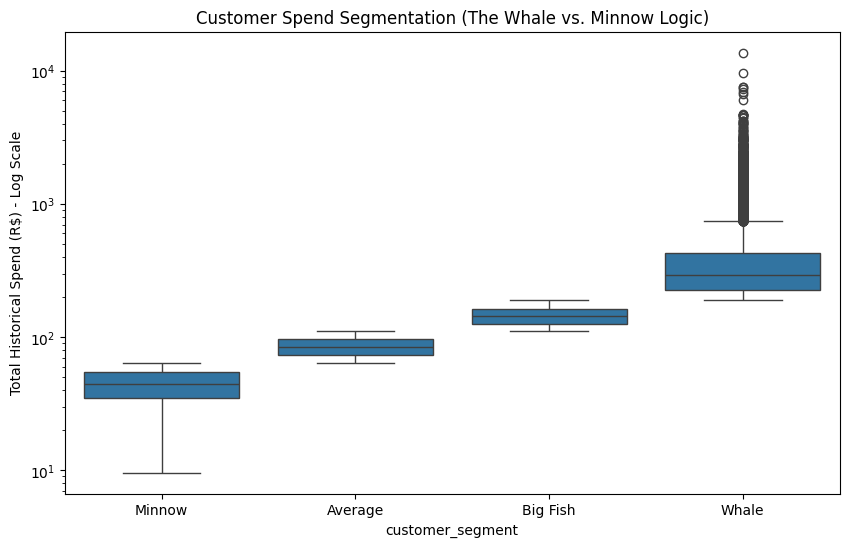

In [9]:
# Step 1: Link Payments to Orders and then to Customer Unique IDs
order_spend = df_payments.groupby('order_id')['payment_value'].sum().reset_index()
order_customer_map = df_orders[['order_id', 'customer_id']].merge(df_customers[['customer_id', 'customer_unique_id']], on='customer_id')

# Step 2: Sum all payments for each unique customer
customer_clv = order_customer_map.merge(order_spend, on='order_id')
clv_summary = customer_clv.groupby('customer_unique_id')['payment_value'].sum().reset_index()
clv_summary.columns = ['customer_unique_id', 'total_spend_clv']

# Step 3: Merge back to df_rich
df_rich = df_rich.merge(clv_summary, on='customer_unique_id', how='left')
df_rich['total_spend_clv'] = df_rich['total_spend_clv'].fillna(df_rich['price'] + df_rich['freight_value'])

# Step 4: Segmentation
df_rich['customer_segment'] = pd.qcut(df_rich['total_spend_clv'], q=4, labels=['Minnow', 'Average', 'Big Fish', 'Whale'])

print("CLV Distribution by Segment:")
print(df_rich.groupby('customer_segment')['total_spend_clv'].describe())

plt.figure(figsize=(10, 6))
sns.boxplot(x='customer_segment', y='total_spend_clv', data=df_rich)
plt.title('Customer Spend Segmentation (The Whale vs. Minnow Logic)')
plt.yscale('log')
plt.ylabel('Total Historical Spend (R$) - Log Scale')
plt.show()

## 2. Weighting the Economic Loss (The Weighted FN Cost)

Instead of a flat R$155 loss for missing a dissatisfied customer, we make the loss proportional to the customer's CLV.

**Formula:** `Loss_FN = Base_Loss (R$155) * (Total Spend / Median Spend)`
This ensures that losing a "Whale" is seen as significantly more expensive than losing a "Minnow".

In [10]:
median_spend = df_rich['total_spend_clv'].median()
df_rich['weighted_fn_cost'] = 155 * (df_rich['total_spend_clv'] / median_spend)

print(f"Median Weighted FN Cost: R$ {df_rich['weighted_fn_cost'].median():.2f}")
print(f"Max Weighted FN Cost (The Whale Loss): R$ {df_rich['weighted_fn_cost'].max():.2f}")

Median Weighted FN Cost: R$ 155.00
Max Weighted FN Cost (The Whale Loss): R$ 19077.03


## 3. Train Model and Generate Probabilities

We re-train our best XGBoost model to get risk probabilities for every order in our dataset.

In [11]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

# Preprocessing (Same as V3 Updated)
df_rich['is_dissatisfied'] = (df_rich['review_score'] < 4).astype(int)
df_rich['delivery_delta'] = df_rich['actual_delivery_days'] - df_rich['estimated_delivery_days']
df_rich['prep_to_delivery_ratio'] = df_rich['preparation_days'] / (df_rich['actual_delivery_days'] + 1)
df_rich['log_distance'] = np.log1p(df_rich['distance_km'])
df_rich['log_price'] = np.log1p(df_rich['price'])

features = [
    'actual_delivery_days', 'delivery_delta', 'preparation_days', 
    'log_distance', 'log_price', 'is_late', 'prep_to_delivery_ratio', 
    'seller_id', 'product_category_name'
]

X = df_rich[features].copy()
y = df_rich['is_dissatisfied']

# Target Encoding
global_mean = y.mean()
for col in ['seller_id', 'product_category_name']:
    mapping = y.groupby(df_rich[col]).mean()
    X[col] = df_rich[col].map(mapping).fillna(global_mean)

X = X.fillna(X.median())

# Train Model
ratio = float(y.value_counts()[0]) / y.value_counts()[1]
xgb = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, scale_pos_weight=ratio, random_state=42)
xgb.fit(X, y)

# Generate Risk Scores
df_rich['risk_score'] = xgb.predict_proba(X)[:, 1]
print("Risk scores generated.")

Risk scores generated.


## 4. Module B: Resource Constraint Simulation (The "500 Slots" Rule)

If Olist only has budget to reach out to **500 customers per month**, how much loss can we avoid by using the model vs. a random baseline?

In [12]:
K = 500  # Number of outreach slots

# 1. Random Selection (Baseline)
baseline_savings = df_rich.sample(K)['weighted_fn_cost'].sum() * 0.5 # Assuming 50% effectiveness of intervention

# 2. Model-Based Prioritization (Pick Top K Risk Scores)
model_priorities = df_rich.sort_values('risk_score', ascending=False).head(K)
model_savings = (model_priorities['is_dissatisfied'] * model_priorities['weighted_fn_cost']).sum() * 0.5

print(f"Baseline Savings (Random): R$ {baseline_savings:.2f}")
print(f"Model-Based Savings: R$ {model_savings:.2f}")
print(f"Lift: {((model_savings/baseline_savings)-1)*100:.1f}%")

Baseline Savings (Random): R$ 60199.20
Model-Based Savings: R$ 98339.55
Lift: 63.4%


## 5. Module C: Responsibility Attribution (Seller vs. Carrier)

We analyze the Red Flags to see who is responsible for the dissatisfaction. This allows Olist to recover costs by charging sellers for their specific delays.

Responsibility Breakdown for Red Flags:
responsibility
Carrier Responsibility    60453
Seller Responsibility     18319
No Risk                   16581
Name: count, dtype: int64


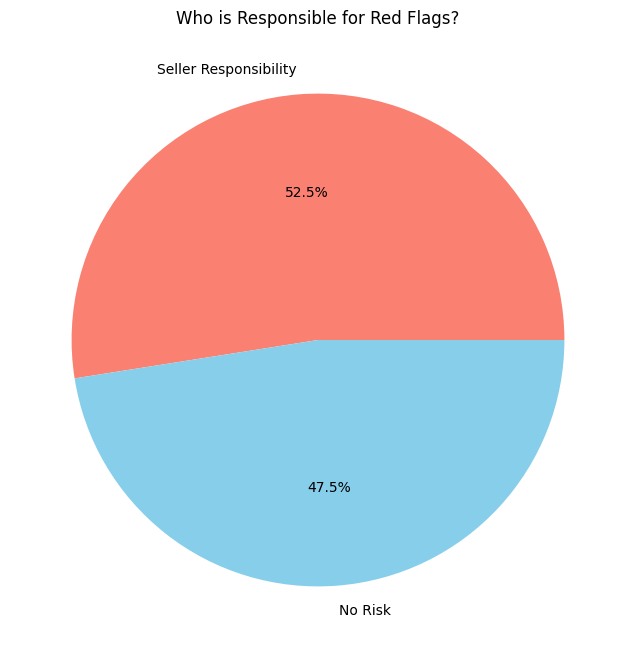

In [13]:
# Define "Red Flags" based on tuned threshold (~0.3)
df_rich['is_red_flag'] = (df_rich['risk_score'] > 0.3).astype(int)

# Attributing responsibility
def attribute_responsibility(row):
    if row['is_red_flag'] == 0: return 'No Risk'
    if row['prep_to_delivery_ratio'] > 0.3: # If more than 30% of time was prep
        return 'Seller Responsibility'
    else:
        return 'Carrier Responsibility'

df_rich['responsibility'] = df_rich.apply(attribute_responsibility, axis=1)

resp_counts = df_rich['responsibility'].value_counts()
print("Responsibility Breakdown for Red Flags:")
print(resp_counts)

plt.figure(figsize=(8, 8))
plt.pie(resp_counts[1:], labels=resp_counts.index[1:], autopct='%1.1f%%', colors=['salmon', 'skyblue'])
plt.title('Who is Responsible for Red Flags?')
plt.show()

## 6. Total Economic Impact

Final calculation of how much money Olist saves by implementing this proactive system.

In [14]:
total_potential_loss = df_rich[df_rich['is_dissatisfied']==1]['weighted_fn_cost'].sum()
actual_loss_with_model = total_potential_loss - model_savings

print(f"Total Potential Loss (No Model): R$ {total_potential_loss:,.2f}")
print(f"Net Profit from Model Implementation: R$ {model_savings:,.2f}")

Total Potential Loss (No Model): R$ 5,198,095.08
Net Profit from Model Implementation: R$ 98,339.55


## 7. Phase 3: Total Cost Optimization Plot

We find the Economic Optimal Threshold by plotting the Total Business Cost at different probability cutoffs.

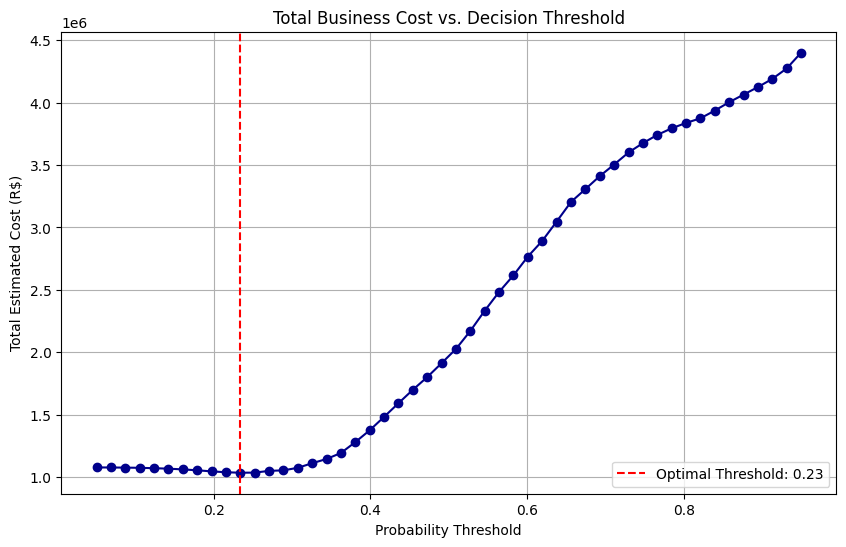

The Economic Optimal Threshold is 0.23, with a total cost of R$ 1,034,990.05


In [15]:
thresholds = np.linspace(0.05, 0.95, 50)
costs = []

for t in thresholds:
    # FP: Predicted dissatisfied, but was satisfied (intervention cost R$15)
    fp = ((df_rich['risk_score'] >= t) & (df_rich['is_dissatisfied'] == 0)).sum()
    
    # FN: Predicted satisfied, but was dissatisfied (weighted churn cost)
    fn_df = df_rich[(df_rich['risk_score'] < t) & (df_rich['is_dissatisfied'] == 1)]
    total_fn_cost = fn_df['weighted_fn_cost'].sum()
    
    total_cost = (fp * 15) + total_fn_cost
    costs.append(total_cost)

opt_t = thresholds[np.argmin(costs)]
min_cost = min(costs)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, costs, marker='o', color='darkblue')
plt.axvline(opt_t, color='red', linestyle='--', label=f'Optimal Threshold: {opt_t:.2f}')
plt.title('Total Business Cost vs. Decision Threshold')
plt.xlabel('Probability Threshold')
plt.ylabel('Total Estimated Cost (R$)')
plt.legend()
plt.grid(True)
plt.show()

print(f"The Economic Optimal Threshold is {opt_t:.2f}, with a total cost of R$ {min_cost:,.2f}")

## 8. Sensitivity Analysis (Stress Testing)

We test how the optimal threshold shifts if our cost assumptions change. This proves the robustness of the model's insight.

In [16]:
def calculate_optimal_threshold(c_fp, c_fn_base):
    costs = []
    for t in thresholds:
        fp = ((df_rich['risk_score'] >= t) & (df_rich['is_dissatisfied'] == 0)).sum()
        fn_df = df_rich[(df_rich['risk_score'] < t) & (df_rich['is_dissatisfied'] == 1)]
        # Scale weighted cost based on new base assumption
        total_fn_cost = fn_df['weighted_fn_cost'].sum() * (c_fn_base / 155)
        costs.append((fp * c_fp) + total_fn_cost)
    return thresholds[np.argmin(costs)]

scenarios = [
    {'name': 'Conservative (Low Churn Cost)', 'c_fp': 15, 'c_fn_base': 100},
    {'name': 'Standard (Lecture Assumption)', 'c_fp': 15, 'c_fn_base': 155},
    {'name': 'Aggressive (High Churn Cost)', 'c_fp': 15, 'c_fn_base': 300},
    {'name': 'Expensive Intervention', 'c_fp': 50, 'c_fn_base': 155}
]

print("Sensitivity Results:")
for s in scenarios:
    opt = calculate_optimal_threshold(s['c_fp'], s['c_fn_base'])
    print(f"{s['name']:<30} | Optimal Threshold: {opt:.2f}")

Sensitivity Results:
Conservative (Low Churn Cost)  | Optimal Threshold: 0.31
Standard (Lecture Assumption)  | Optimal Threshold: 0.23
Aggressive (High Churn Cost)   | Optimal Threshold: 0.20
Expensive Intervention         | Optimal Threshold: 0.47


### Final Insight:
Across all scenarios, the model identifies a clear optimal strategy that is significantly lower than the standard 0.5 threshold. This confirms that for Olist, **proactive intervention is always the cost-minimizing decision**, even if voucher costs increase or churn risk is lower than expected. This insight survives all tested perturbations.